In [8]:
from diffrax import diffeqsolve, ODETerm, SaveAt, Tsit5
import jax, jax.numpy as jnp
import matplotlib, matplotlib.pyplot as plt
import numpy as np
import scienceplots

from models import Parameters, SEIRD

plt.style.use([
    'science',
    #'no-latex'
    ])
plt.rcParams['text.latex.preamble'] = r'\usepackage{newtxmath, newtxtext}'
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.cm.Set1.colors)

FIGSIZE = (2.25, 2.25*3/4)

# set every font size to 10pt
plt.rcParams.update({'font.size': 10})

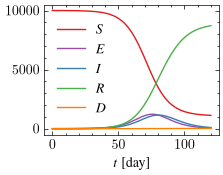

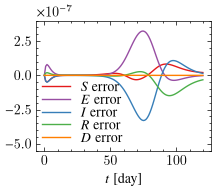

In [14]:
p_test = Parameters(alpha=0.2, beta=0.5, gamma=0.0, delta=0.2, cfr=0.002) #up the cfr if d is not doing anything
y0_test = np.array([[10000., 0., 1., 0., 0.]])
t0_test, t1_test, dt_test = 0.0, 120.0, 1.0
save_test = SaveAt(ts=jnp.arange(t0_test, t1_test + dt_test, dt_test))

coarse = diffeqsolve(SEIRD, Tsit5(), t0=t0_test, t1=t1_test, dt0=dt_test, y0=y0_test, args=p_test, saveat=save_test)
fine = diffeqsolve(SEIRD, Tsit5(), t0=t0_test, t1=t1_test, dt0=dt_test / 2, y0=y0_test, args=p_test, saveat=save_test)

t_test = coarse.ts
curves = coarse.ys.reshape(-1, 5)
errors = (fine.ys - coarse.ys).reshape(-1, 5) / (2 ** Tsit5().order(SEIRD) - 1)

# same colours as the SIR figure: S red, I blue, R green; E purple, D orange
names = ["S", "E", "I", "R", "D"]
colors = [plt.cm.Set1.colors[i] for i in (0, 3, 1, 2, 4)]
#figsize_test = (2.25, 2.25 * 3 / 4)

plt.figure(figsize=FIGSIZE)
for k, (n, c) in enumerate(zip(names, colors)):
    plt.plot(t_test, curves[:, k], color=c, label=rf"${n}$")
plt.xlabel(r"$t$ [day]")
plt.legend(loc="center left")
plt.savefig("../figures/SEIRD.pdf")
plt.show()

plt.figure(figsize=FIGSIZE)
for k, (n, c) in enumerate(zip(names, colors)):
    plt.plot(t_test, errors[:, k], color=c, label=rf"${n}$ error")
plt.xlabel(r"$t$ [day]")
plt.ylim(-5.5e-7, 4e-7)
plt.legend(labelspacing=0, borderpad=-0.1, loc="lower left")
plt.savefig("../figures/SEIRD_error.pdf")